# 02. Анализ A/B-теста нового алгоритма рекомендаций

Гипотеза и метрика → Дизайн: MDE и размер выборки → **Проверка: A/A и SRM → Анализ A/B → Сегменты → Решение**

Дизайн эксперимента (гипотеза, метрики, α, мощность, MDE) зафиксирован в `01_experiment_design.ipynb`. Основная метрика — глобальный CTR группы, проверка — t-тест на линеаризованных лайках и пуассоновский бутстрап.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import ab_utils as ab

sns.set_theme(style="whitegrid")
connection = ab.get_connection()

In [2]:
CONTROL, TEST = ab.CONTROL_GROUP, ab.TEST_GROUP
pd.Series({
    "Основная метрика": ab.PRIMARY_METRIC,
    "alpha": ab.ALPHA,
    "Контроль / тест": f"{CONTROL} / {TEST}",
    "Период": f"{ab.EXP_PERIOD['start']} — {ab.EXP_PERIOD['end']}",
})

Основная метрика                 global_ctr
alpha                                  0.05
Контроль / тест                       1 / 2
Период              2026-08-28 — 2026-09-03
dtype: object

## 1. Проверка корректности эксперимента

### 1.1. SRM: соответствует ли деление пользователей задуманному 50/50

Если размеры групп значимо отличаются от ожидаемых, сплитование сломано, и результатам теста доверять нельзя. Для SRM обычно берут строгий порог p < 0.001.

In [3]:
sizes = ab.fetch("group_sizes", connection, groups=ab.GROUPS, **ab.EXP_PERIOD)
sizes

,exp_group,users
0,1,10020
1,2,9877


In [4]:
srm = ab.srm_test(sizes.users)
srm

{'chi2': 1.0277428758104237, 'p_value': 0.3106893913980353, 'srm': False}

### 1.2. A/A на неделе до эксперимента

До запуска алгоритма группы должны быть одинаковы по целевой метрике.

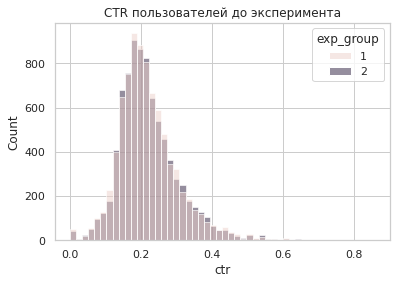

In [5]:
df_aa = ab.fetch("user_metrics", connection, groups=ab.GROUPS, **ab.PRE_PERIOD)

sns.histplot(data=df_aa, x="ctr", hue="exp_group", bins=50)
plt.title("CTR пользователей до эксперимента")
plt.show()

In [6]:
pd.Series(ab.compare_ctr(df_aa, CONTROL, TEST))

n_a                       8491.000000
n_b                       8362.000000
ctr_a                        0.210760
ctr_b                        0.211730
abs_diff                     0.000970
rel_diff                     0.004603
p_linearized                 0.387871
p_ttest_user_ctr             0.569030
p_mannwhitney_user_ctr       0.744478
dtype: float64

Одного теста мало: проверим, что сам критерий не ошибается чаще заявленных 5%. Для этого 10 000 раз берём подвыборки по 500 пользователей из каждой группы и считаем долю p-value < 0.05.

In [7]:
p_aa = ab.aa_simulation(df_aa, CONTROL, TEST, n_iter=10000, sample_size=500, seed=42)
fpr = ab.false_positive_rate(p_aa)
fpr

0.0492

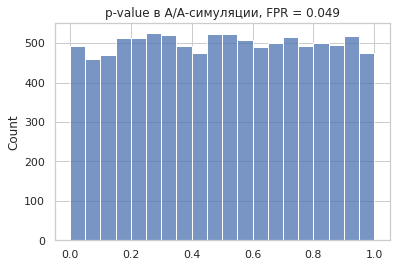

In [8]:
sns.histplot(p_aa, bins=20)
plt.title(f"p-value в A/A-симуляции, FPR = {fpr:.3f}")
plt.show()

Распределения CTR в группах практически совпадают, различие в A/A-тесте незначимо. Доля ложных срабатываний близка к 5%, а p-value распределены примерно равномерно. Значит, группы однородны по целевой метрике, и критерий работает корректно.

## 2. Анализ A/B-теста

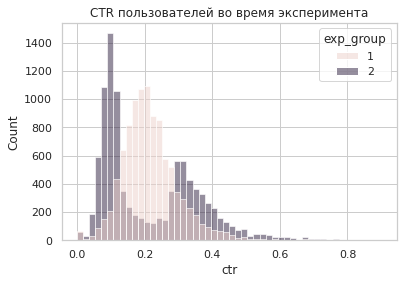

In [9]:
df = ab.fetch("user_metrics", connection, groups=ab.GROUPS, **ab.EXP_PERIOD)

sns.histplot(data=df, x="ctr", hue="exp_group", bins=50)
plt.title("CTR пользователей во время эксперимента")
plt.savefig("../images/ctr_distribution.png", dpi=120)
plt.show()

Распределение CTR в тестовой группе стало бимодальным. У меньшей части пользователей CTR заметно вырос (пик около 0.3), а у большинства снизился (пик около 0.1).

In [10]:
result = ab.compare_ctr(df, CONTROL, TEST)
pd.Series(result)

n_a                       1.002000e+04
n_b                       9.877000e+03
ctr_a                     2.096042e-01
ctr_b                     2.002505e-01
abs_diff                 -9.353653e-03
rel_diff                 -4.462532e-02
p_linearized              2.980506e-09
p_ttest_user_ctr          6.853733e-01
p_mannwhitney_user_ctr    4.632206e-45
dtype: float64

Разные тесты дают разные ответы, и это следствие формы распределения:

- **t-тест на CTR пользователей** сравнивает средние. При бимодальности рост у одной части и падение у другой могут почти уравновесить друг друга, поэтому различие незначимо.
- **Тест Манна–Уитни** проверяет сдвиг распределений, а не средних. Он фиксирует, что распределения разные, но не говорит, в какую сторону изменился средний CTR.
- **t-тест на линеаризованных лайках** проверяет именно основную метрику — глобальный CTR — и учитывает, что у пользователей разное число просмотров.

In [11]:
boot = ab.bootstrap_ctr_diff(df, CONTROL, TEST, n_bootstrap=2000, seed=42)
print(f"Разница глобального CTR (тест − контроль): {result['abs_diff']:.4f}")
print(f"95% ДИ бутстрапа: [{boot['ci_low']:.4f}; {boot['ci_high']:.4f}], p = {boot['p_value']:.4f}")

Разница глобального CTR (тест − контроль): -0.0094
95% ДИ бутстрапа: [-0.0124; -0.0064], p = 0.0000


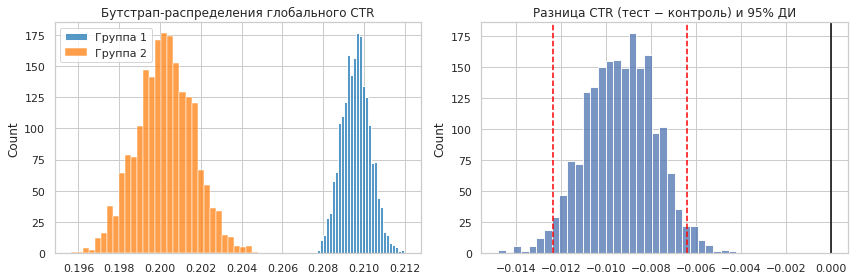

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(boot["ctr_a"], color="tab:blue", label=f"Группа {CONTROL}", ax=axes[0])
sns.histplot(boot["ctr_b"], color="tab:orange", label=f"Группа {TEST}", ax=axes[0])
axes[0].set_title("Бутстрап-распределения глобального CTR")
axes[0].legend()
sns.histplot(boot["diff"], ax=axes[1])
axes[1].axvline(0, color="black")
axes[1].axvline(boot["ci_low"], color="red", linestyle="--")
axes[1].axvline(boot["ci_high"], color="red", linestyle="--")
axes[1].set_title("Разница CTR (тест − контроль) и 95% ДИ")
plt.tight_layout()
plt.savefig("../images/bootstrap_ctr.png", dpi=120)
plt.show()

Бутстрап-распределения глобального CTR групп почти не пересекаются. Если доверительный интервал разницы целиком лежит по одну сторону от нуля, изменение основной метрики статистически значимо, а знак интервала показывает направление эффекта.

### 2.1. Бакетный анализ

Пользователи делятся на 50 бакетов по хешу `user_id`, внутри бакета считаются глобальный и медианный CTR. Метрики бакетов распределены почти нормально, поэтому их можно сравнивать обычными тестами.

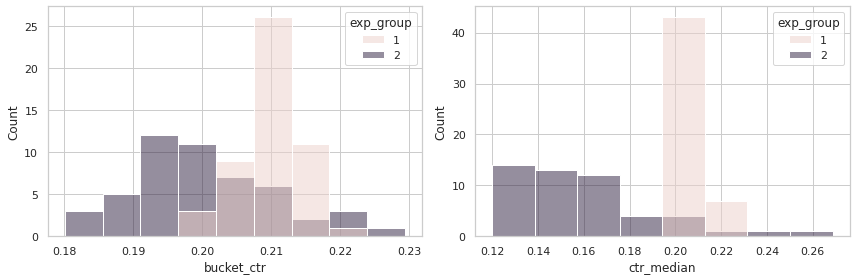

In [13]:
df_bucket = ab.fetch("bucket_metrics", connection, groups=ab.GROUPS, n_buckets=50, **ab.EXP_PERIOD)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df_bucket, x="bucket_ctr", hue="exp_group", ax=axes[0])
sns.histplot(data=df_bucket, x="ctr_median", hue="exp_group", ax=axes[1])
plt.tight_layout()
plt.show()

In [14]:
pd.DataFrame({
    "bucket_ctr": ab.bucket_test(df_bucket, CONTROL, TEST, metric="bucket_ctr"),
    "ctr_median": ab.bucket_test(df_bucket, CONTROL, TEST, metric="ctr_median"),
})

,bucket_ctr,ctr_median
mean_a,2.096936e-01,2.057239e-01
mean_b,2.004567e-01,1.601376e-01
p_ttest,4.592645e-07,2.626814e-14
p_mannwhitney,2.657643e-07,1.828291e-13


Бакетный анализ проверяет тот же вывод независимым способом. Медианный CTR бакета показывает, что происходит с типичным пользователем, а не со средним.

### 2.2. Ограничительные метрики

In [15]:
guardrails = ab.guardrail_check(df, CONTROL, TEST)
guardrails

,metric,mean_a,mean_b,rel_diff,p_value,violated
0,views_per_user,66.820659,66.766630,-0.000809,0.933063,False
1,likes_per_user,14.005888,13.370052,-0.045398,0.000038,True


## 3. Сегменты: почему эффект неоднородный

Бимодальность показывает, что алгоритм действует на разных пользователей по-разному. Проверим гипотезы о причинах на данных.

Сегменты строятся только по признакам, на которые алгоритм не мог повлиять: активность берётся за неделю **до** эксперимента, а ОС, источник трафика и возраст не зависят от ленты. Если делить по просмотрам во время теста, сам алгоритм будет перекладывать пользователей между сегментами, и сравнение станет смещённым.

In [16]:
attrs = ab.fetch("user_attributes", connection, groups=ab.GROUPS, **ab.EXP_PERIOD)
pre_views = df_aa[["user_id", "views"]].rename(columns={"views": "pre_views"})

seg = (
    df.merge(pre_views, on="user_id", how="left")
      .merge(attrs, on="user_id", how="left")
)
seg["activity"] = pd.cut(
    seg.pre_views.fillna(0),
    bins=[-1, 0, 20, 50, 100, np.inf],
    labels=["новые", "1–20", "21–50", "51–100", "100+"],
)
seg["age_group"] = pd.cut(seg.age, bins=[0, 17, 25, 35, 45, 120], labels=["<18", "18–25", "26–35", "36–45", "45+"])
seg[["activity", "os", "source", "age_group"]].describe()

,activity,os,source,age_group
count,19897,19897,19897,19897
unique,5,2,2,5
top,новые,Android,organic,18–25
freq,7586,12859,10579,8450


In [17]:
segment_cols = {
    "activity": "Активность до теста (просмотров за неделю)",
    "os": "ОС",
    "source": "Источник трафика",
    "age_group": "Возраст",
}

segments = pd.concat(
    [
        ab.segment_effects(seg, col, CONTROL, TEST, n_bootstrap=1000, seed=42)
          .rename(columns={col: "segment"})
          .assign(dimension=col)
        for col in segment_cols
    ],
    ignore_index=True,
)
segments["p_bonferroni"] = (segments.p_linearized * len(segments)).clip(upper=1)
segments[["dimension", "segment", "n_a", "n_b", "ctr_a", "ctr_b", "abs_diff", "ci_low", "ci_high", "p_bonferroni"]]

,dimension,segment,n_a,n_b,ctr_a,ctr_b,abs_diff,ci_low,ci_high,p_bonferroni
0,activity,новые,3818,3768,0.211791,0.201198,-0.010592,-0.015323,-0.006024,0.000341
1,activity,1–20,697,667,0.208199,0.198268,-0.009931,-0.021889,0.002701,1.000000
2,activity,21–50,1757,1758,0.210265,0.199472,-0.010792,-0.017829,-0.002541,0.076300
3,activity,51–100,2282,2235,0.206693,0.199454,-0.007240,-0.013122,-0.000639,0.376463
4,activity,100+,1466,1449,0.207970,0.200714,-0.007256,-0.015576,0.001163,1.000000
5,os,Android,6494,6365,0.209811,0.202179,-0.007631,-0.011643,-0.003770,0.001484
6,os,iOS,3526,3512,0.209228,0.196811,-0.012417,-0.017285,-0.007525,0.000034
7,source,ads,4676,4642,0.211703,0.202996,-0.008707,-0.013420,-0.004104,0.003451
8,source,organic,5344,5235,0.207957,0.198075,-0.009882,-0.013763,-0.005653,0.000038
9,age_group,<18,1362,1266,0.206932,0.205473,-0.001458,-0.009706,0.007435,1.000000


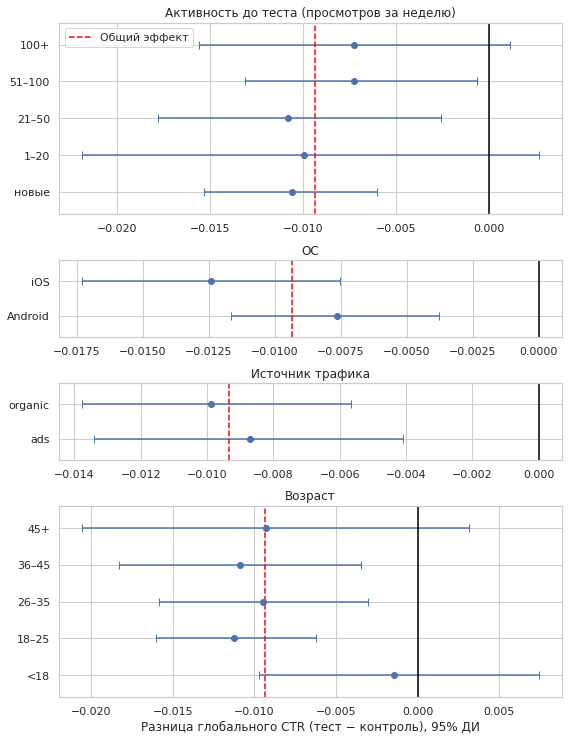

In [18]:
heights = [max(segments.dimension.eq(c).sum(), 2) for c in segment_cols]
fig, axes = plt.subplots(len(segment_cols), 1, figsize=(8, 0.6 * sum(heights) + 2), gridspec_kw={"height_ratios": heights})
for ax, (col, title) in zip(axes, segment_cols.items()):
    part = segments[segments.dimension == col]
    y = np.arange(len(part))
    ax.errorbar(
        part.abs_diff, y,
        xerr=[part.abs_diff - part.ci_low, part.ci_high - part.abs_diff],
        fmt="o", capsize=4,
    )
    ax.axvline(0, color="black")
    ax.axvline(result["abs_diff"], color="red", linestyle="--", label="Общий эффект")
    ax.set_ylim(-0.6, len(part) - 0.4)
    ax.set_yticks(y)
    ax.set_yticklabels(part.segment.astype(str))
    ax.set_title(title)
axes[0].legend()
axes[-1].set_xlabel("Разница глобального CTR (тест − контроль), 95% ДИ")
plt.tight_layout()
plt.savefig("../images/segments.png", dpi=120)
plt.show()

In [19]:
def effect_direction(row):
    if row.ci_low > 0:
        return "рост"
    if row.ci_high < 0:
        return "падение"
    return "не значимо"

segments["effect"] = segments.apply(effect_direction, axis=1)
segments.groupby(["dimension", "effect"]).segment.apply(lambda s: ", ".join(map(str, s))).unstack(fill_value="—")

effect,не значимо,падение
dimension,,
activity,"1–20, 100+","новые, 21–50, 51–100"
age_group,"<18, 45+","18–25, 26–35, 36–45"
os,—,"Android, iOS"
source,—,"ads, organic"


Как читать результат:

- Если знак эффекта различается по сегментам **активности**, подтверждается гипотеза о «тяжёлых» и «лёгких» пользователях: алгоритм подходит одной группе и не подходит другой.
- Если падение сосредоточено в одной **ОС**, вероятна техническая причина (некорректная работа или задержки загрузки на определённых устройствах).
- Различия по **источнику трафика** и **возрасту** указывают на разницу в интересах аудитории, под которые алгоритм перекосил выдачу.
- Гипотезу о времени суток эти данные не проверяют: для этого нужен разрез по часам просмотров.

Сегментов много, поэтому p-value скорректированы поправкой Бонферрони. Сегментный анализ подсказывает причины, но не доказывает их: найденные закономерности стоит проверять отдельным экспериментом. Можем увидеть, что падение произошло практически по всем сегментам. Исключением являются пользователи с очень высокой (100+ просмотров) и очень низкой (<20 просмотров) активностью, а также пользователи в возрасте <18 лет и 45+.

## 4. Решение

In [20]:
if boot["ci_high"] < 0:
    decision = "Не раскатывать: глобальный CTR значимо снизился"
elif boot["ci_low"] > 0 and not guardrails.violated.any():
    decision = "Раскатывать: CTR значимо вырос, ограничительные метрики в норме"
elif boot["ci_low"] > 0:
    decision = "Не раскатывать без доработки: CTR вырос, но нарушены ограничительные метрики"
else:
    decision = "Эффект не доказан: изменение CTR меньше чувствительности теста"

pd.Series({
    "SRM": "есть" if srm["srm"] else "нет",
    "FPR в A/A": round(fpr, 3),
    "CTR контроль": round(result["ctr_a"], 4),
    "CTR тест": round(result["ctr_b"], 4),
    "Разница, абс.": round(result["abs_diff"], 4),
    "Разница, отн.": f"{result['rel_diff']:.1%}",
    "95% ДИ": f"[{boot['ci_low']:.4f}; {boot['ci_high']:.4f}]",
    "p (линеаризация)": result["p_linearized"],
    "Нарушенные guardrails": ", ".join(guardrails.loc[guardrails.violated, "metric"]) or "нет",
    "Решение": decision,
})

SRM                                                                  нет
FPR в A/A                                                          0.049
CTR контроль                                                      0.2096
CTR тест                                                          0.2003
Разница, абс.                                                    -0.0094
Разница, отн.                                                      -4.5%
95% ДИ                                                [-0.0124; -0.0064]
p (линеаризация)                                                     0.0
Нарушенные guardrails                                     likes_per_user
Решение                  Не раскатывать: глобальный CTR значимо снизился
dtype: object

**Вывод.** Новый алгоритм рекомендаций оказывает статистически значимый негативный эффект на основную метрику:

- Основная гипотеза о росте CTR не подтвердилась: доверительный интервал разницы глобального CTR целиком лежит в отрицательной зоне.
- Эффект неоднороден: у меньшей части аудитории CTR вырос, у большинства — снизился. Сегментный анализ показывает, у кого именно.
- Падение CTR означает, что пользователи хуже находят релевантный контент. Это риск оттока, который сложно остановить после раскатки.

**Рекомендация:** не раскатывать новый алгоритм на всех пользователей.

**Следующие шаги:** разобраться, почему алгоритм работает для сегментов с ростом CTR; доработать его для остальных; проверить доработанную версию новым экспериментом, рассчитав размер выборки в `01_experiment_design.ipynb`.